In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [8]:
df = pd.read_csv('data/ecommerce_dataset.csv')

In [9]:
df.drop(columns=['product_id','external_id','subcategory', 'url','images_count', 'first_image', 'tags' ,'scraped_at'], inplace=True)

## Frequecies

In [12]:
# relative frequencies

availability = df['availability'].value_counts(normalize=True)

print(availability)
print(np.sum(availability))

availability
in_stock        0.834
out_of_stock    0.085
limited         0.081
Name: proportion, dtype: float64
0.9999999999999999


In [18]:
freq_table = pd.crosstab(df['source'],df['availability'], normalize='all')

print(freq_table)
print(np.sum(freq_table))

availability  in_stock  limited  out_of_stock
source                                       
aliexpress       0.165    0.015         0.020
amazon           0.168    0.016         0.016
ebay             0.162    0.016         0.022
jumia            0.169    0.019         0.012
noon             0.170    0.015         0.015
1.0


## Quantiles and distribution measures

### Quantiles

- Qunatiles - quartiles (1/4 pf dataset), deciles (1/10), percentiles (1/100)
- Median is percentile

In [19]:
q1 = df['price_current'].quantile(0.25)
q3 = df['price_current'].quantile(0.75)
iqr = q3 - q1

q2 = df['price_current'].quantile(0.5)
price_median = df['price_current'].median()


print(f"Q1: {q1}\nQ3: {q3}\nIQR: {iqr}")
print(f"{price_median} - {q2}")

Q1: 438.3075
Q3: 5227.9325
IQR: 4789.625
1723.325 - 1723.325


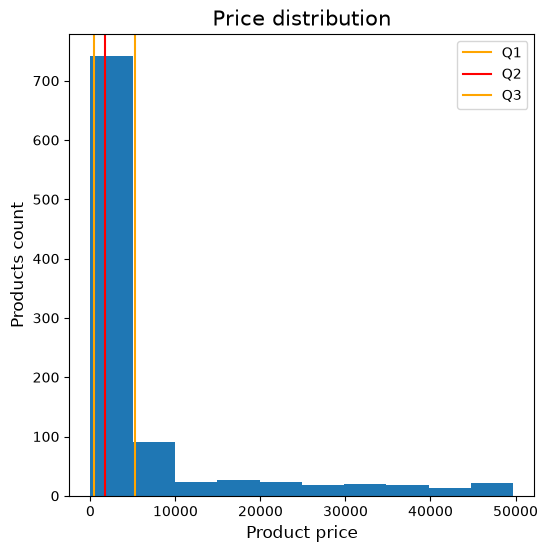

In [22]:
plt.figure(figsize=[6,6])

plt.hist(df['price_current'])
plt.title("Price distribution", fontsize= 15)
plt.xlabel("Product price", fontsize= 12)
plt.ylabel("Products count", fontsize= 12)

plt.axvline(q1, color='orange', linestyle = '-', label="Q1")
plt.axvline(q2, color='r', linestyle = '-', label="Q2")
plt.axvline(q3, color='orange', linestyle = '-', label="Q3")

plt.legend()

plt.show()


## Distribution measures

In [38]:
p_median = df['price_current'].median()
mean = df['price_current'].mean()
p_mode = df['price_current'].mode()[0]


### Skewness

- positive (right skew) - mean > median > mode
- nefgative (left skew) - mean < median < mode
- no skewness - mean = median = mode

In [41]:
skew = df['price_current'].skew()

print(f"Mean - Median: {mean - median}")
print(f"Skewness: {skew}")

Mean - Median: 4545.47044
Skewness: 2.3602595117960465


### Kurtosois

- Leptokurtic (heavy-tailed) - extreme outliers, value > 0
- Mesokurtic (normal-like distribution) - distribution resembles normal curve (normal distribution has 0 kurt), value close to 0
- Platykurtic (light-tailed) - data is more evenly distributed ,value < 0

In [42]:
print(f"Kurtosis: {df['price_current'].kurtosis()}")

Kurtosis: 4.6492653289232635


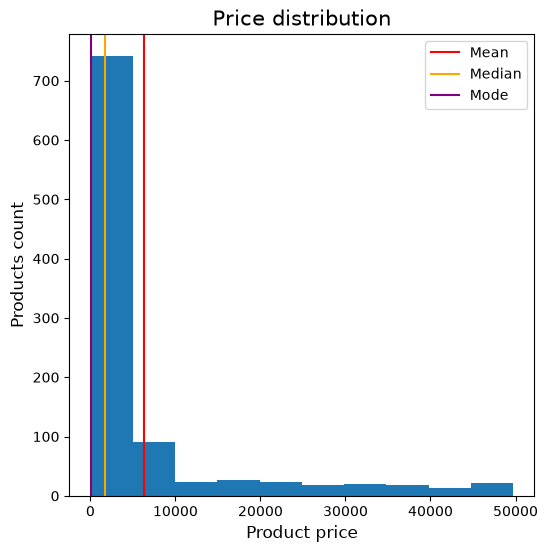

In [40]:
plt.figure(figsize=[6,6])

plt.hist(df['price_current'])
plt.title("Price distribution", fontsize= 15)
plt.xlabel("Product price", fontsize= 12)
plt.ylabel("Products count", fontsize= 12)

plt.axvline(mean, color='r', linestyle = '-', label="Mean")
plt.axvline(p_median, color='orange', linestyle = '-', label="Median")
plt.axvline(p_mode, color='purple', linestyle = '-', label="Mode")

plt.legend()

plt.show()
